# Task 4 — Evaluation and critical discussion
**Md Soad Solaiman · a1978974**

This notebook checks and evaluates the saved Task 3 out-of-fold predictions. It does not train or tune models. Model settings, activity labels, participants, window rules and feature definitions remain unchanged.

We report pooled metrics, variation between participants, activity-level results, confusion matrices and measured computation. A paired participant-cluster bootstrap describes uncertainty without treating overlapping windows as independent. The small sample and shared cross-validation training sets still limit that uncertainty analysis.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from IPython.display import display, Markdown

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from src.evaluation import CLASSES, ACTIVITIES, scores, metrics_from_counts
from src.statistical_analysis import cluster_bootstrap
from src.evaluation_plots import COLORS, set_style, save_plot

set_style()
RESULTS = REPO_ROOT / 'results'
GENERATED_NOTES = RESULTS / 'generated_notes'
GENERATED_NOTES.mkdir(parents=True, exist_ok=True)
predictions = pd.read_csv(RESULTS / 'task3_oof_predictions.csv.gz')
metadata = pd.read_csv(RESULTS / 'window_metadata.csv').set_index('window_id')
manifest = pd.read_csv(RESULTS / 'task3_experiment_manifest.csv')
old_pooled = pd.read_csv(RESULTS / 'task3_overall_metrics.csv').set_index('model')
old_folds = pd.read_csv(RESULTS / 'task3_fold_metrics.csv').set_index(['model', 'participant'])
runtimes = pd.read_csv(RESULTS / 'task3_fold_runtimes.csv')
config = json.loads((RESULTS / 'task3_model_config.json').read_text())
models = manifest.model.tolist()
people = sorted(metadata.participant.unique())
METRICS = ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
PROB_COLUMNS = [f'p_{label}' for label in CLASSES]
FEATURE, DECISION = 'Feature fusion', 'Decision fusion'
ACC, GYRO = 'Accelerometers (all locations)', 'Gyroscopes (ankle + wrist)'

## 4.1 Validate the saved predictions
Before interpretation, we check that every experiment contains one prediction per eligible window, all ten test participants, identical labels and the correct probability order. Predictions must match the maximum aligned probability. Metrics are recomputed from saved predictions and compared with Task 3 tables.

These checks complement Task 3's actual training-split assertions; prediction files alone cannot prove which data a model saw during fitting.

In [2]:
assert set(predictions.model) == set(models)
assert not predictions.duplicated(['model', 'window_id']).any()
assert not predictions.isna().any().any()
assert config['classes'] == CLASSES.tolist()
assert hashlib.sha256((RESULTS / 'window_features.csv.gz').read_bytes()).hexdigest() == config['feature_sha256']
assert hashlib.sha256((RESULTS / 'window_metadata.csv').read_bytes()).hexdigest() == config['metadata_sha256']
assert np.allclose(predictions[PROB_COLUMNS].sum(axis=1), 1)
assert predictions[PROB_COLUMNS].ge(0).all().all() and predictions[PROB_COLUMNS].le(1).all().all()
pooled_rows, participant_rows, activity_rows, matrix_rows = [], [], [], []
matrices = {}
for name in models:
    group = predictions[predictions.model == name].set_index('window_id').loc[metadata.index]
    assert len(group) == len(metadata)
    assert set(group.participant) == set(people)
    assert np.array_equal(group.true_label, metadata.activity)
    assert np.array_equal(group.participant, metadata.participant)
    assert np.array_equal(group.fold, metadata.participant)
    assert np.array_equal(group.predicted_label, CLASSES[group[PROB_COLUMNS].to_numpy().argmax(axis=1)])
    pooled_result = scores(group.true_label, group.predicted_label)
    assert np.allclose([pooled_result[m] for m in METRICS], old_pooled.loc[name, METRICS].to_numpy(float))
    pooled_rows.append({'model': name, **pooled_result})
    for participant, part in group.groupby('participant'):
        result = scores(part.true_label, part.predicted_label)
        assert np.allclose([result[m] for m in METRICS], old_folds.loc[(name, participant), METRICS].to_numpy(float))
        participant_rows.append({'model': name, 'participant': participant, 'windows': len(part), **result})
    precision, recall, f1, support = precision_recall_fscore_support(
        group.true_label, group.predicted_label, labels=CLASSES, zero_division=0)
    cm = confusion_matrix(group.true_label, group.predicted_label, labels=CLASSES)
    matrices[name] = cm
    assert cm.sum() == len(metadata)
    assert np.array_equal(cm.sum(axis=1), support)
    for j, label in enumerate(CLASSES):
        activity_rows.append({'model': name, 'activity': int(label), 'activity_name': ACTIVITIES[j],
                              'precision': precision[j], 'recall': recall[j], 'f1': f1[j], 'support': support[j]})
        for k, predicted_label in enumerate(CLASSES):
            matrix_rows.append({'model': name, 'true_label': int(label), 'predicted_label': int(predicted_label),
                                'count': int(cm[j, k]), 'row_fraction': cm[j, k] / support[j]})
pooled = pd.DataFrame(pooled_rows).set_index('model')
participant_metrics = pd.DataFrame(participant_rows)
per_activity = pd.DataFrame(activity_rows)
confusions = pd.DataFrame(matrix_rows)
pooled.to_csv(RESULTS / 'task4_model_comparison.csv')
participant_metrics.to_csv(RESULTS / 'task4_participant_metrics.csv', index=False)
per_activity.to_csv(RESULTS / 'task4_per_activity_metrics.csv', index=False)
confusions.to_csv(RESULTS / 'task4_confusion_matrices.csv', index=False)
print('Verified: all 7 models, 10 participants, 4,581 windows per model, and reproduced metrics.')
# Check that the saved fusion is exactly the declared equal average.
component_probabilities = {}
for name in [ACC, GYRO, DECISION]:
    component_probabilities[name] = predictions[predictions.model == name].set_index('window_id').loc[metadata.index, PROB_COLUMNS].to_numpy()
assert np.allclose(component_probabilities[DECISION],
                   (component_probabilities[ACC] + component_probabilities[GYRO]) / 2)


Verified: all 7 models, 10 participants, 4,581 windows per model, and reproduced metrics.


## 4.2 Overall comparison
The four required metrics are calculated from pooled out-of-fold predictions. All precision, recall and F1 calculations use explicit zero-division handling (`0`). Macro metrics give each of the 12 activities equal weight. The displayed table uses percentages; saved CSV metrics use proportions.

The strongest unimodal comparator is selected by pooled macro F1 from the five non-fusion baselines. This is a descriptive, post-hoc ranking of these results, not independent model selection evidence.

Strongest unimodal baseline by pooled macro F1: Accelerometers (all locations)


,accuracy (%),macro_precision (%),macro_recall (%),macro_f1 (%)
model,,,,
Chest accelerometer,82.71,84.32,83.55,83.40
Ankle accelerometer,85.96,87.81,86.91,87.09
Wrist accelerometer,73.96,75.29,73.39,73.74
Accelerometers (all locations),96.81,97.22,96.79,96.91
Gyroscopes (ankle + wrist),78.63,78.42,74.86,75.28
Feature fusion,96.44,96.85,96.34,96.51
Decision fusion,96.44,96.87,96.21,96.45


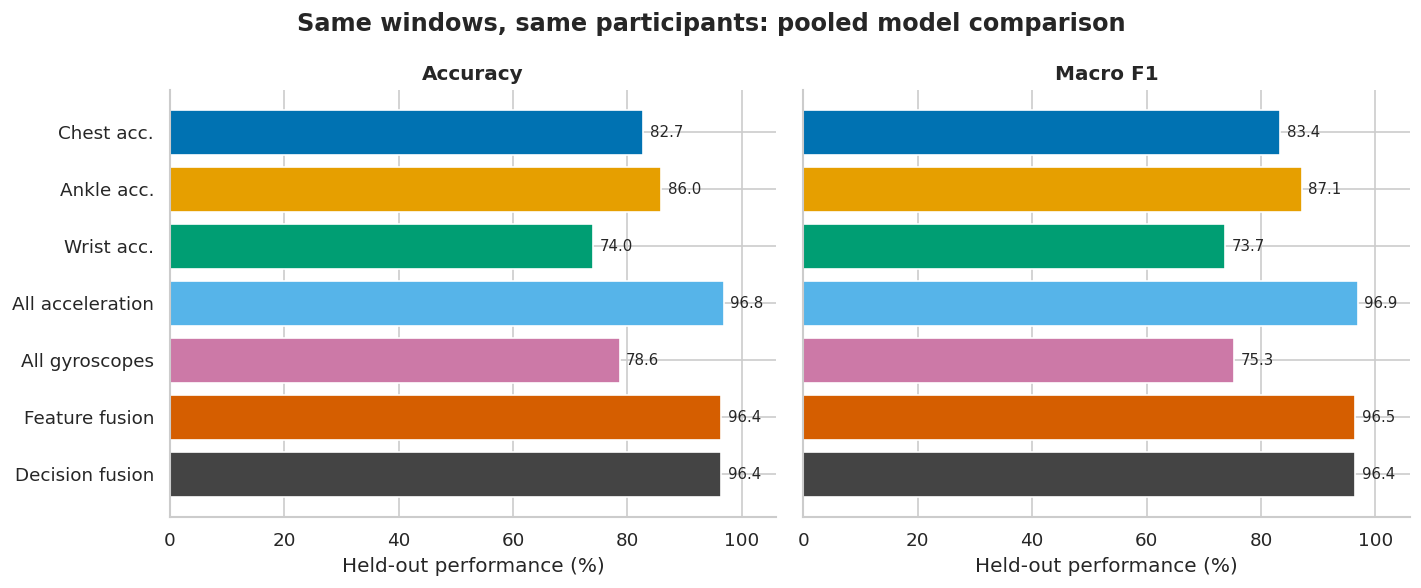

In [3]:
baselines = [name for name in models if name not in [FEATURE, DECISION]]
best_baseline = pooled.loc[baselines, 'macro_f1'].idxmax()
best_overall = pooled.macro_f1.idxmax()
display((pooled * 100).round(2).rename(columns={m: m + ' (%)' for m in METRICS}))
print('Strongest unimodal baseline by pooled macro F1:', best_baseline)

short_names = {'Chest accelerometer': 'Chest acc.', 'Ankle accelerometer': 'Ankle acc.',
               'Wrist accelerometer': 'Wrist acc.', ACC: 'All acceleration', GYRO: 'All gyroscopes',
               FEATURE: 'Feature fusion', DECISION: 'Decision fusion'}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, metric in zip(axes, ['accuracy', 'macro_f1']):
    values = pooled.loc[models, metric].to_numpy() * 100
    bars = ax.barh(range(len(models)), values, color=COLORS)
    ax.set(yticks=range(len(models)), yticklabels=[short_names[m] for m in models],
           xlim=(0, 106), xlabel='Held-out performance (%)',
           title='Accuracy' if metric == 'accuracy' else 'Macro F1')
    ax.bar_label(bars, labels=[f'{v:.1f}' for v in values], padding=4, fontsize=9)
axes[0].invert_yaxis()
fig.suptitle('Same windows, same participants: pooled model comparison', fontweight='bold')
fig.tight_layout()
save_plot(fig, '05_model_comparison')

## 4.3 Participant variation and matched improvements
A pooled metric weights participants through their contributed predictions. The mean participant metric instead gives each participant equal weight; both are reported separately. Participant summaries include mean, sample standard deviation, median, minimum and maximum.

Fusion differences below are **absolute percentage points**. Paired comparisons use the same participants and windows. More positive participant differences indicate greater consistency, but do not establish statistical significance.

model,Chest accelerometer,Ankle accelerometer,Wrist accelerometer,Accelerometers (all locations),Gyroscopes (ankle + wrist),Feature fusion,Decision fusion
participant,,,,,,,
1,79.45,80.04,81.62,99.79,67.28,98.55,97.52
2,69.45,88.19,64.71,87.87,56.17,92.22,88.58
3,94.02,91.37,69.82,83.70,90.92,88.70,86.58
4,82.35,82.42,63.22,91.83,90.60,96.60,98.25
5,91.52,88.75,79.61,99.80,68.06,99.80,100.00
6,85.16,77.02,75.50,99.79,61.71,85.83,95.70
7,69.84,84.64,44.23,100.00,68.37,100.00,99.10
8,67.14,91.40,71.47,98.91,48.32,98.90,91.87
9,87.60,97.09,89.43,99.80,81.39,100.00,100.00


,fusion,comparator,metric,pooled_difference_pp,mean_participant_difference_pp,participant_sd_pp,participants_better,participants_worse,participants_tied
7,Feature fusion,Accelerometers (all locations),macro_f1,-0.400,-0.068,5.406,5,3,2
19,Decision fusion,Accelerometers (all locations),macro_f1,-0.467,-0.388,3.663,6,4,0


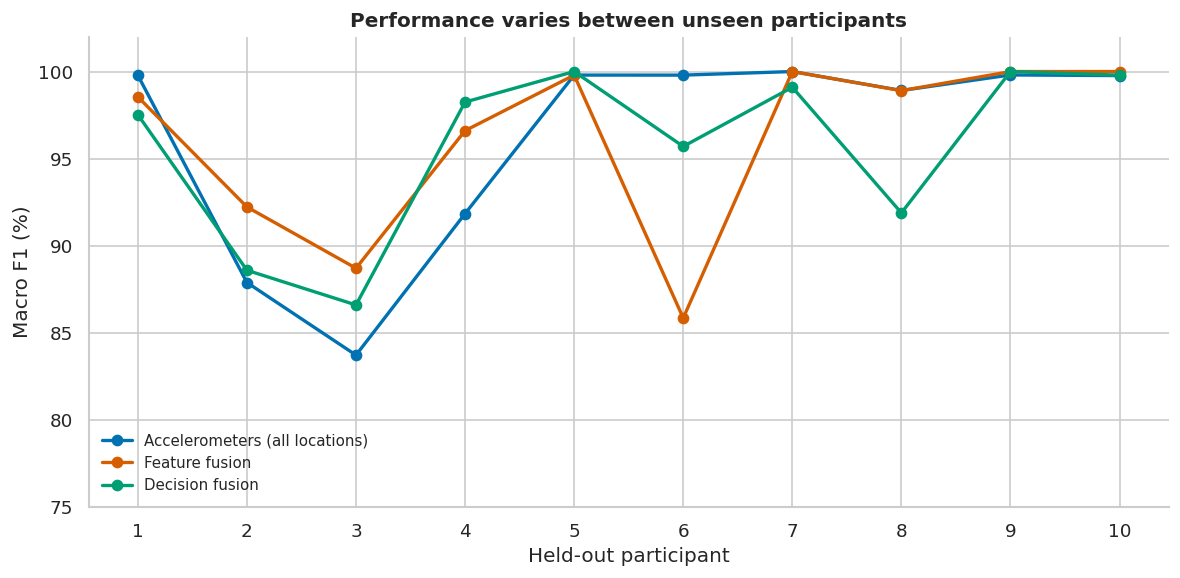

In [4]:
participant_summary = participant_metrics.groupby('model', sort=False)[METRICS].agg(['mean', 'std', 'median', 'min', 'max'])
participant_summary.to_csv(RESULTS / 'task4_participant_summary.csv')
participant_table = participant_metrics.pivot(index='participant', columns='model', values='macro_f1')[models]
participant_table.to_csv(RESULTS / 'task4_participant_by_model.csv')
display((participant_table * 100).round(2))
improvement_rows, paired_rows = [], []
for fusion in [FEATURE, DECISION]:
    comparators = baselines + ([DECISION] if fusion == FEATURE else [FEATURE])
    for baseline in comparators:
        for metric in ['accuracy', 'macro_f1']:
            wide = participant_metrics.pivot(index='participant', columns='model', values=metric)
            delta = (wide[fusion] - wide[baseline]) * 100
            improvement_rows.append({'fusion': fusion, 'comparator': baseline, 'metric': metric,
                'pooled_difference_pp': 100 * (pooled.loc[fusion, metric] - pooled.loc[baseline, metric]),
                'mean_participant_difference_pp': delta.mean(), 'participant_sd_pp': delta.std(),
                'participants_better': int((delta > 1e-12).sum()),
                'participants_worse': int((delta < -1e-12).sum()),
                'participants_tied': int(np.isclose(delta, 0, atol=1e-12).sum())})
            for participant, difference in delta.items():
                paired_rows.append({'fusion': fusion, 'comparator': baseline, 'metric': metric,
                                    'participant': participant, 'difference_pp': difference})
improvements = pd.DataFrame(improvement_rows)
improvements.to_csv(RESULTS / 'task4_fusion_improvements.csv', index=False)
pd.DataFrame(paired_rows).to_csv(RESULTS / 'task4_paired_participant_differences.csv', index=False)
display(improvements[(improvements.comparator == best_baseline) & (improvements.metric == 'macro_f1')].round(3))

fig, ax = plt.subplots(figsize=(10, 5))
for name, color in zip([best_baseline, FEATURE, DECISION], [COLORS[0], COLORS[5], COLORS[2]]):
    ax.plot(participant_table.index, participant_table[name] * 100, marker='o', linewidth=2, color=color, label=name)
ax.set(xticks=people, xlabel='Held-out participant', ylabel='Macro F1 (%)', ylim=(75, 102),
       title='Performance varies between unseen participants')
ax.legend(frameon=False, fontsize=9, loc='lower left')
fig.tight_layout()
save_plot(fig, '06_participant_variation')

## 4.4 Activity results and confusion patterns
Per-activity precision describes how often predictions of an activity are correct; recall describes how much of the true activity is recovered. The saved table contains both, F1 and support for every model. The figure compares the strongest unimodal baseline and both fusion models with identical class ordering and a common 0–100% scale. Rows are true activities; columns are predictions.

Count matrices for every model are saved alongside row-normalised values in `task4_confusion_matrices.csv`. The largest off-diagonal entries are examined explicitly below.

model,Accelerometers (all locations),Feature fusion,Decision fusion
activity_name,,,
Standing,95.28,95.28,95.16
Sitting,94.80,94.80,94.80
Lying down,100.00,100.00,100.00
Walking,99.88,99.88,99.76
Climbing stairs,99.29,99.06,95.48
Waist bends,99.87,100.00,99.87
Arm elevation,100.00,100.00,100.00
Knees bending,99.10,98.72,94.23
Cycling,99.88,99.63,99.63


,model,true_activity,predicted_activity,count,row_fraction
561,Accelerometers (all locations),Running,Jogging,69,0.172
444,Accelerometers (all locations),Sitting,Standing,41,0.099
550,Accelerometers (all locations),Jogging,Running,24,0.058
876,Decision fusion,Sitting,Standing,41,0.099
952,Decision fusion,Knees bending,Climbing stairs,40,0.102
993,Decision fusion,Running,Jogging,40,0.100
849,Feature fusion,Running,Jogging,70,0.175
732,Feature fusion,Sitting,Standing,41,0.099
838,Feature fusion,Jogging,Running,35,0.084


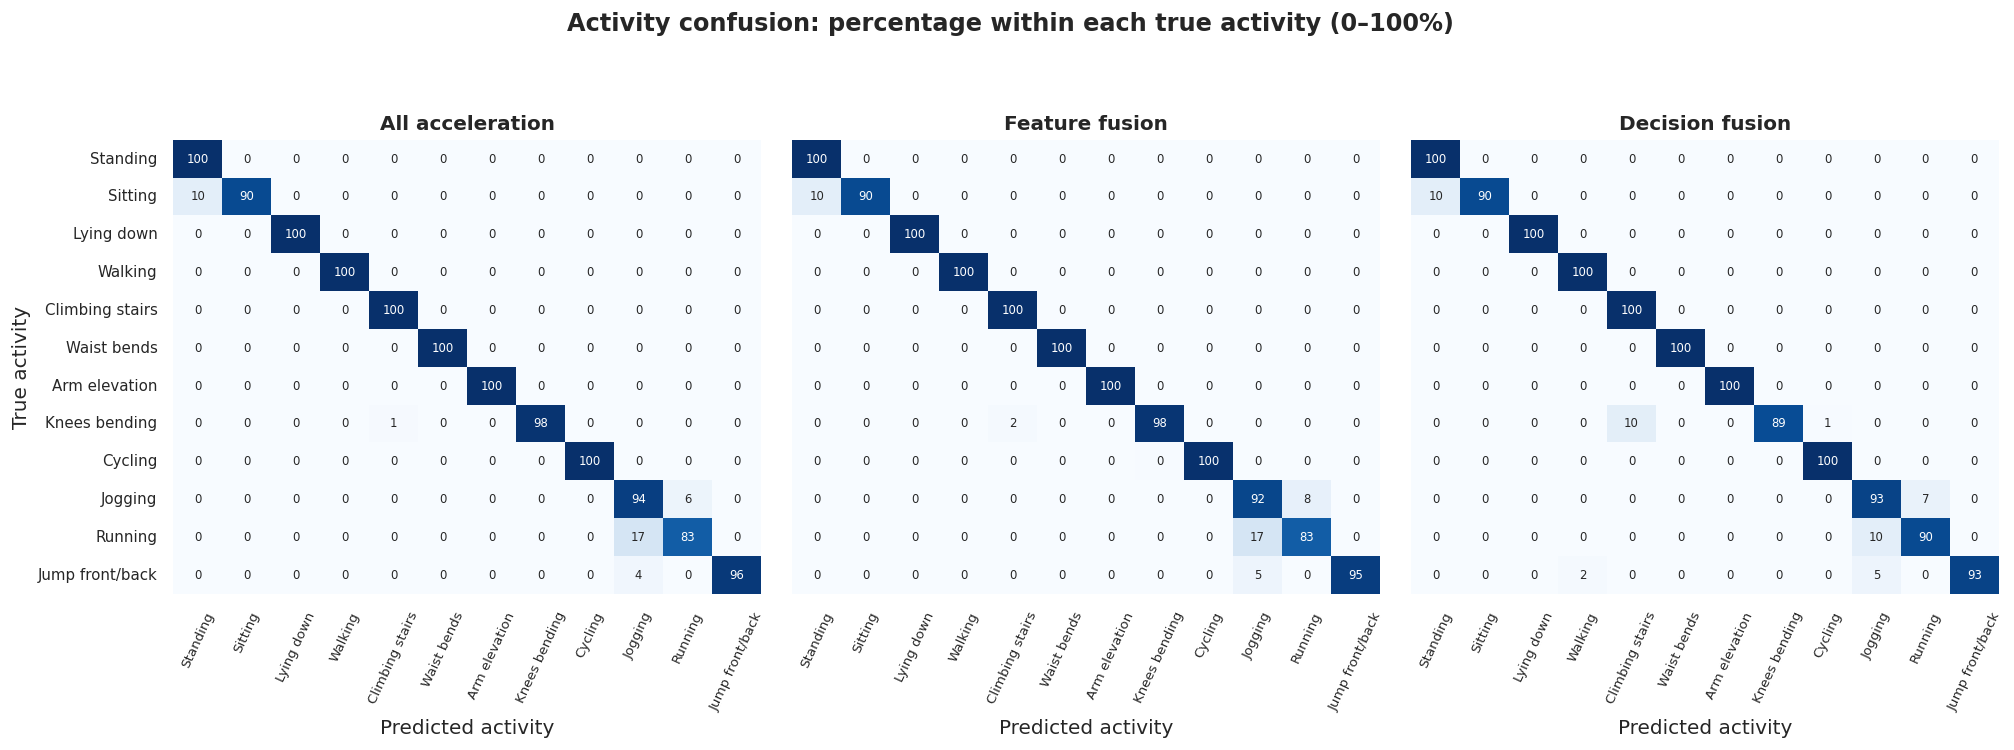

In [5]:
activity_f1 = per_activity.pivot(index='activity_name', columns='model', values='f1').reindex(ACTIVITIES)
display((activity_f1[[best_baseline, FEATURE, DECISION]] * 100).round(2))
activity_deltas = []
for fusion in [FEATURE, DECISION]:
    for baseline in baselines + ([DECISION] if fusion == FEATURE else [FEATURE]):
        for activity in ACTIVITIES:
            activity_deltas.append({'fusion': fusion, 'comparator': baseline, 'activity': activity,
                'f1_difference_pp': 100 * (activity_f1.loc[activity, fusion] - activity_f1.loc[activity, baseline])})
activity_deltas = pd.DataFrame(activity_deltas)
activity_deltas.to_csv(RESULTS / 'task4_activity_fusion_differences.csv', index=False)
selected_models = [best_baseline, FEATURE, DECISION]
pairs = confusions[confusions.true_label != confusions.predicted_label].copy()
pairs['true_activity'] = pairs.true_label.map(dict(zip(CLASSES, ACTIVITIES)))
pairs['predicted_activity'] = pairs.predicted_label.map(dict(zip(CLASSES, ACTIVITIES)))
top_pairs = pairs.sort_values(['model', 'count'], ascending=[True, False]).groupby('model', sort=False).head(3)
top_pairs.to_csv(RESULTS / 'task4_top_confusion_pairs.csv', index=False)
display(top_pairs[top_pairs.model.isin(selected_models)][['model', 'true_activity', 'predicted_activity', 'count', 'row_fraction']].round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 6.3))
for i, (ax, name) in enumerate(zip(axes, selected_models)):
    cm = matrices[name]
    normalised = cm / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(normalised, ax=ax, cmap='Blues', vmin=0, vmax=100, annot=True, fmt='.0f',
                annot_kws={'fontsize': 7}, cbar=False, xticklabels=ACTIVITIES,
                yticklabels=ACTIVITIES if i == 0 else False)
    ax.set(title=short_names[name], xlabel='Predicted activity', ylabel='True activity' if i == 0 else '')
    ax.tick_params(axis='x', rotation=65, labelsize=8)
    ax.tick_params(axis='y', rotation=0, labelsize=9)
fig.suptitle('Activity confusion: percentage within each true activity (0–100%)', fontweight='bold', y=.99)
fig.tight_layout(rect=(0, 0, 1, .94))
save_plot(fig, '07_confusion_matrices')

## 4.5 Participant-aware uncertainty
We resample the **ten participants as whole clusters**, 2,000 times with seed 42. All windows belonging to each sampled participant are retained, including multiplicity when a participant is sampled more than once. The same bootstrap draw is used across all models, so fusion differences are paired. We recompute pooled accuracy and macro F1 from the resampled confusion counts and report 2.5th–97.5th percentile intervals.

These exploratory intervals are conditional on the already fitted out-of-fold models. They do not include retraining variability, and overlapping training sets make cross-validation estimates dependent. With only ten participants, intervals can be unstable. The strongest baseline was identified using these same results, so comparisons against it also involve post-hoc selection. We make no formal significance claim.

In [6]:
participant_cms = np.zeros((len(models), len(people), 12, 12), dtype=int)
for i, name in enumerate(models):
    for j, participant in enumerate(people):
        part = predictions[(predictions.model == name) & (predictions.participant == participant)]
        participant_cms[i, j] = confusion_matrix(part.true_label, part.predicted_label, labels=CLASSES)
    assert np.array_equal(participant_cms[i].sum(axis=0), matrices[name])
    check_acc, check_f1 = metrics_from_counts(participant_cms[i].sum(axis=0))
    assert np.isclose(check_acc, pooled.loc[name, 'accuracy'])
    assert np.isclose(check_f1, pooled.loc[name, 'macro_f1'])
bootstrap = cluster_bootstrap(participant_cms, repeats=2000, seed=42)
uncertainty_rows = []
for metric, samples in bootstrap.items():
    for i, name in enumerate(models):
        low, high = np.percentile(samples[:, i], [2.5, 97.5])
        uncertainty_rows.append({'model': name, 'metric': metric,
                                 'estimate': pooled.loc[name, metric], 'lower': low, 'upper': high})
uncertainty = pd.DataFrame(uncertainty_rows)
uncertainty.to_csv(RESULTS / 'task4_uncertainty_summary.csv', index=False)
interval_rows = []
for row in improvements.itertuples(index=False):
    samples = bootstrap[row.metric]
    difference = 100 * (samples[:, models.index(row.fusion)] - samples[:, models.index(row.comparator)])
    low, high = np.percentile(difference, [2.5, 97.5])
    interval_rows.append({'fusion': row.fusion, 'comparator': row.comparator, 'metric': row.metric,
                          'estimate_pp': row.pooled_difference_pp, 'lower_pp': low, 'upper_pp': high})
paired_intervals = pd.DataFrame(interval_rows)
paired_intervals.to_csv(RESULTS / 'task4_fusion_uncertainty.csv', index=False)
display(uncertainty[uncertainty.metric == 'macro_f1'].round(4))
display(paired_intervals[(paired_intervals.comparator == best_baseline) &
                         (paired_intervals.metric == 'macro_f1')].round(3))
# Independently check one resample using the prediction rows themselves.
weights = np.random.default_rng(42).multinomial(len(people), np.full(len(people), 1 / len(people)))
for i, name in enumerate(models):
    sampled = pd.concat([predictions[(predictions.model == name) & (predictions.participant == person)]
                         for person, count in zip(people, weights) for _ in range(count)])
    check = scores(sampled.true_label, sampled.predicted_label)
    assert np.isclose(check['accuracy'], bootstrap['accuracy'][0, i])
    assert np.isclose(check['macro_f1'], bootstrap['macro_f1'][0, i])


,model,metric,estimate,lower,upper
7,Chest accelerometer,macro_f1,0.8340,0.7808,0.8821
8,Ankle accelerometer,macro_f1,0.8709,0.8284,0.9081
9,Wrist accelerometer,macro_f1,0.7374,0.6673,0.7977
10,Accelerometers (all locations),macro_f1,0.9691,0.9392,0.9964
11,Gyroscopes (ankle + wrist),macro_f1,0.7528,0.6757,0.8280
12,Feature fusion,macro_f1,0.9651,0.9349,0.9900
13,Decision fusion,macro_f1,0.9645,0.9400,0.9853


,fusion,comparator,metric,estimate_pp,lower_pp,upper_pp
7,Feature fusion,Accelerometers (all locations),macro_f1,-0.400,-3.723,1.96
19,Decision fusion,Accelerometers (all locations),macro_f1,-0.467,-2.177,1.25


## 4.6 Computational comparison
Times below are seconds summed over ten folds, not time for one deployed model. Decision fusion includes both modality models. Its components reuse baseline fits, so summing costs across all experiment rows would double-count them. Task 2 feature extraction is not included. Training and prediction were measured once per fold in this environment using a single worker; small differences should not be interpreted as universal speed advantages.

More channels require additional sensing, storage and preprocessing. Sensor synchronisation, battery demand, bandwidth and calibration can matter in deployment, but none was measured here. Model size and peak memory were also not measured.

In [7]:
assert not runtimes.duplicated(['model', 'fold']).any()
assert runtimes.groupby('model').size().eq(10).all()
assert (runtimes[['train_seconds', 'prediction_seconds', 'total_seconds']] >= 0).all().all()
assert np.allclose(runtimes.total_seconds, runtimes.train_seconds + runtimes.prediction_seconds)
for fold, group in runtimes.groupby('fold'):
    r = group.set_index('model')
    assert np.isclose(r.loc[DECISION, 'train_seconds'], r.loc[ACC, 'train_seconds'] + r.loc[GYRO, 'train_seconds'])
    assert r.loc[DECISION, 'prediction_seconds'] >= r.loc[ACC, 'prediction_seconds'] + r.loc[GYRO, 'prediction_seconds']
computational = manifest.merge(runtimes.groupby('model', sort=False)[['train_seconds', 'prediction_seconds', 'total_seconds']].sum(), on='model')
computational.to_csv(RESULTS / 'task4_computational_comparison.csv', index=False)
display(computational.round(3))

,model,features,sources,modalities,component_models,train_seconds,prediction_seconds,total_seconds
0,Chest accelerometer,18,1,1,1,19.071,0.108,19.179
1,Ankle accelerometer,18,1,1,1,18.587,0.109,18.697
2,Wrist accelerometer,18,1,1,1,19.438,0.117,19.555
3,Accelerometers (all locations),54,3,1,1,25.403,0.091,25.494
4,Gyroscopes (ankle + wrist),36,2,1,1,23.818,0.107,23.925
5,Feature fusion,90,3,2,1,31.224,0.100,31.325
6,Decision fusion,90,3,2,2,49.220,0.198,49.418


## 4.7 Interpret the measured results
The discussion below is generated directly from the saved metrics. It separates measured differences from possible explanations. A high score on these retained, annotation-segmented windows is not evidence of real-time or external deployment performance.

In [8]:
lines = ['### Overall findings']
lines.append(f'The strongest unimodal baseline was **{best_baseline}**, with '
             f'{pooled.loc[best_baseline, "accuracy"] * 100:.2f}% accuracy and '
             f'{pooled.loc[best_baseline, "macro_f1"] * 100:.2f}% macro F1 (Figure 5).')
for fusion in [FEATURE, DECISION]:
    result = improvements[(improvements.fusion == fusion) & (improvements.comparator == best_baseline) &
                          (improvements.metric == 'macro_f1')].iloc[0]
    interval = paired_intervals[(paired_intervals.fusion == fusion) & (paired_intervals.comparator == best_baseline) &
                                 (paired_intervals.metric == 'macro_f1')].iloc[0]
    lines.append(f'**{fusion}** achieved {pooled.loc[fusion, "accuracy"] * 100:.2f}% accuracy and '
                 f'{pooled.loc[fusion, "macro_f1"] * 100:.2f}% macro F1. Its pooled macro F1 difference '
                 f'from the strongest baseline was {result.pooled_difference_pp:+.2f} percentage points. '
                 f'It improved {result.participants_better} participants, worsened {result.participants_worse} '
                 f'and tied for {result.participants_tied}. The paired participant-cluster interval for '
                 f'the pooled difference was [{interval.lower_pp:+.2f}, {interval.upper_pp:+.2f}] points. '
                 'This is exploratory uncertainty, not a significance test.')
lines.append(f'Feature fusion minus decision fusion was '
             f'{100 * (pooled.loc[FEATURE, "macro_f1"] - pooled.loc[DECISION, "macro_f1"]):+.2f} '
             'macro F1 points. These small differences should be read alongside participant variation, '
             'rather than treated as decisive evidence of a universally better method.')
lines.append('### Participant variation')
for name in [best_baseline, FEATURE, DECISION]:
    values = participant_table[name]
    lines.append(f'{name}: mean participant macro F1 {values.mean() * 100:.2f}%, '
                 f'SD {values.std() * 100:.2f} points, minimum {values.min() * 100:.2f}% '
                 f'(participant {values.idxmin()}) and maximum {values.max() * 100:.2f}% '
                 f'(participant {values.idxmax()}).')
stability = participant_table[[FEATURE, DECISION]].std()
lines.append(f'{stability.idxmin()} had the smaller descriptive between-participant macro F1 SD '
             f'({stability.min() * 100:.2f} points); the other fusion SD was {stability.max() * 100:.2f} '
             'points (Figure 6). These ten participants are insufficient to establish general stability. '
             'No causal analysis links participant errors to movement style or recording quality.')
lines.append('### Activities and confusions')
for name in [best_baseline, FEATURE, DECISION]:
    activity = per_activity[per_activity.model == name].set_index('activity_name')
    worst, best = activity.f1.idxmin(), activity.f1.idxmax()
    low_recall, low_precision = activity.recall.idxmin(), activity.precision.idxmin()
    lines.append(f'{name}: lowest activity F1 was {worst} ({activity.loc[worst, "f1"] * 100:.2f}%; '
                 f'{int(activity.loc[worst, "support"])} windows). A highest-scoring activity was '
                 f'{best} ({activity.loc[best, "f1"] * 100:.2f}%). Lowest recall was '
                 f'{low_recall} ({activity.loc[low_recall, "recall"] * 100:.2f}%) and lowest precision '
                 f'was {low_precision} ({activity.loc[low_precision, "precision"] * 100:.2f}%).')
    for pair in top_pairs[top_pairs.model == name].head(2).itertuples(index=False):
        lines.append(f'For {name}, {pair.true_activity} was predicted as {pair.predicted_activity} '
                     f'in {pair.count} windows ({pair.row_fraction * 100:.2f}% of that true class; Figure 7).')
for fusion in [FEATURE, DECISION]:
    deltas = activity_deltas[(activity_deltas.fusion == fusion) & (activity_deltas.comparator == best_baseline)]
    gained = deltas.sort_values('f1_difference_pp', ascending=False).iloc[0]
    lost = deltas.sort_values('f1_difference_pp').iloc[0]
    lines.append(f'{fusion} versus the strongest baseline: largest activity F1 change upward was '
                 f'{gained.activity} ({gained.f1_difference_pp:+.2f} points); largest change downward '
                 f'was {lost.activity} ({lost.f1_difference_pp:+.2f} points).')
lines.append('Different motion activities can share similar local amplitude summaries. That is a plausible '
             'explanation for some confusion, but the experiment did not test causal mechanisms or inspect '
             'error-linked raw waveforms. F1 differences do not prove which physiological or biomechanical '
             'factor caused an error.')
lines.append('### Fusion and computation')
compute = computational.set_index('model')
for name in [best_baseline, FEATURE, DECISION]:
    r = compute.loc[name]
    lines.append(f'{name} used {int(r.features)} features and {int(r.component_models)} component model(s). '
                 f'Across ten folds, training took {r.train_seconds:.3f} s and prediction '
                 f'{r.prediction_seconds:.3f} s; their measured sum was {r.total_seconds:.3f} s.')
lines.append('Feature fusion permits within-tree splits across modalities but adds dimensions that can be '
             'redundant. Decision fusion is modular, yet equal averaging gives both components influence '
             'even when their predictive performance differs. The observed component results make that a '
             'plausible reason for mixed fusion performance, but neither redundancy nor probability '
             'calibration was directly tested. Neither approach is highly transparent at the individual '
             'prediction level, and no feature-attribution analysis was conducted. Both require aligned '
             'inputs in this implementation. Decision fusion could be adapted to missing sensors, '
             'but this code requires both components and no sensor-failure robustness was measured.')
interpretation = '\n\n'.join(lines)
display(Markdown(interpretation))

### Overall findings

The strongest unimodal baseline was **Accelerometers (all locations)**, with 96.81% accuracy and 96.91% macro F1 (Figure 5).

**Feature fusion** achieved 96.44% accuracy and 96.51% macro F1. Its pooled macro F1 difference from the strongest baseline was -0.40 percentage points. It improved 5 participants, worsened 3 and tied for 2. The paired participant-cluster interval for the pooled difference was [-3.72, +1.96] points. This is exploratory uncertainty, not a significance test.

**Decision fusion** achieved 96.44% accuracy and 96.45% macro F1. Its pooled macro F1 difference from the strongest baseline was -0.47 percentage points. It improved 6 participants, worsened 4 and tied for 0. The paired participant-cluster interval for the pooled difference was [-2.18, +1.25] points. This is exploratory uncertainty, not a significance test.

Feature fusion minus decision fusion was +0.07 macro F1 points. These small differences should be read alongside participant variation, rather than treated as decisive evidence of a universally better method.

### Participant variation

Accelerometers (all locations): mean participant macro F1 96.13%, SD 6.06 points, minimum 83.70% (participant 3) and maximum 100.00% (participant 7).

Feature fusion: mean participant macro F1 96.06%, SD 5.26 points, minimum 85.83% (participant 6) and maximum 100.00% (participant 7).

Decision fusion: mean participant macro F1 95.74%, SD 4.98 points, minimum 86.58% (participant 3) and maximum 100.00% (participant 5).

Decision fusion had the smaller descriptive between-participant macro F1 SD (4.98 points); the other fusion SD was 5.26 points (Figure 6). These ten participants are insufficient to establish general stability. No causal analysis links participant errors to movement style or recording quality.

### Activities and confusions

Accelerometers (all locations): lowest activity F1 was Running (87.71%; 401 windows). A highest-scoring activity was Lying down (100.00%). Lowest recall was Running (82.79%) and lowest precision was Jogging (84.30%).

For Accelerometers (all locations), Running was predicted as Jogging in 69 windows (17.21% of that true class; Figure 7).

For Accelerometers (all locations), Sitting was predicted as Standing in 41 windows (9.88% of that true class; Figure 7).

Feature fusion: lowest activity F1 was Running (86.31%; 401 windows). A highest-scoring activity was Lying down (100.00%). Lowest recall was Running (82.54%) and lowest precision was Jogging (83.37%).

For Feature fusion, Running was predicted as Jogging in 70 windows (17.46% of that true class; Figure 7).

For Feature fusion, Sitting was predicted as Standing in 41 windows (9.88% of that true class; Figure 7).

Decision fusion: lowest activity F1 was Jogging (91.04%; 416 windows). A highest-scoring activity was Lying down (100.00%). Lowest recall was Knees bending (89.31%) and lowest precision was Jogging (89.35%).

For Decision fusion, Sitting was predicted as Standing in 41 windows (9.88% of that true class; Figure 7).

For Decision fusion, Knees bending was predicted as Climbing stairs in 40 windows (10.18% of that true class; Figure 7).

Feature fusion versus the strongest baseline: largest activity F1 change upward was Waist bends (+0.13 points); largest change downward was Jogging (-1.70 points).

Decision fusion versus the strongest baseline: largest activity F1 change upward was Running (+3.45 points); largest change downward was Knees bending (-4.87 points).

Different motion activities can share similar local amplitude summaries. That is a plausible explanation for some confusion, but the experiment did not test causal mechanisms or inspect error-linked raw waveforms. F1 differences do not prove which physiological or biomechanical factor caused an error.

### Fusion and computation

Accelerometers (all locations) used 54 features and 1 component model(s). Across ten folds, training took 25.403 s and prediction 0.091 s; their measured sum was 25.494 s.

Feature fusion used 90 features and 1 component model(s). Across ten folds, training took 31.224 s and prediction 0.100 s; their measured sum was 31.325 s.

Decision fusion used 90 features and 2 component model(s). Across ten folds, training took 49.220 s and prediction 0.198 s; their measured sum was 49.418 s.

Feature fusion permits within-tree splits across modalities but adds dimensions that can be redundant. Decision fusion is modular, yet equal averaging gives both components influence even when their predictive performance differs. The observed component results make that a plausible reason for mixed fusion performance, but neither redundancy nor probability calibration was directly tested. Neither approach is highly transparent at the individual prediction level, and no feature-attribution analysis was conducted. Both require aligned inputs in this implementation. Decision fusion could be adapted to missing sensors, but this code requires both components and no sensor-failure robustness was measured.

## 4.8 Ethical considerations
Movement and physiological signals can reveal routines and sensitive health-related information. Although the models here use movement channels, the supplied dataset also contains ECG; access to the raw archive therefore deserves protection. Participants should understand the purpose, sensors, retention period, possible secondary uses and consequences of withdrawal, with ongoing consent rather than a one-time blanket agreement.

A deployed service would need clear ownership and access rights, encrypted storage and transmission, restricted access, retention limits and deletion procedures. Data breaches could reveal private routines or inferred health information. Reusing records for workplace surveillance, insurance decisions or other purposes would require separate justification and appropriate consent; this analysis provides no basis for those uses.

Incorrect predictions could trigger inappropriate alerts or adverse decisions. Users should know when automated inference is being used, be able to challenge errors and retain control over participation. Human review is needed where errors have serious consequences. The available files do not provide demographic information, so fairness across age, sex, disability, health status or cultural groups cannot be assessed. Comparing ten participants does not establish demographic fairness or suitability for clinical, employment, insurance or safety-critical deployment.

## 4.9 Limitations and targeted improvements
- **Ten participants and no external validation:** held-out participant testing reduces person overlap but does not establish performance in a broader population. Recruit more diverse participants and test on an independent dataset.
- **Structured, labelled activity recordings:** predefined activity segments are easier to evaluate than unconstrained daily-life streams. The original documentation describes out-of-lab collection; it should not be called a laboratory-only dataset. Evaluate continuous streams with unknown transitions and additional activities.
- **Known activity boundaries:** Task 2 uses annotations to separate segments. Those labels would be unavailable when a deployed system predicts activities; a continuous-stream experiment is necessary.
- **Modified files and unknown missingness:** the timing and origin of missing values are not independently verified. Investigate the adaptation process and compare realistic dropout patterns. No robustness claim follows from filling existing gaps.
- **Offline interpolation:** using future observations can smooth peaks and is unavailable for immediate predictions. Compare one-sided or online handling, under a fixed evaluation design.
- **Common all-channel eligibility:** Task 2 exclusions also depended on ECG and magnetometer channels that the models do not use. Report this restricted population; future comparisons could predefine a selected-channel population and assess whether exclusions alter class or participant coverage.
- **Overlapping windows and annotation uncertainty:** windows share samples, and no independent annotation-quality audit was available. Window counts overstate independent evidence. Participant-aware uncertainty helps but is limited by ten clusters and shared training sets.
- **Hand-crafted statistics and one classifier:** temporal ordering within a window is lost. Fixed forest settings are not optimality evidence. Consider grouped tuning or temporal models as future experiments, without changing parameters in response to these outer-fold results.
- **Uncalibrated equal-weight fusion:** probability reliability and sensor failure were not tested. Given the actual comparison, prioritise grouped, training-only calibration or weighting and explicit sensor-dropout tests before adding model complexity.
- **One timing environment:** runtime excludes acquisition and feature extraction, and memory, energy and bandwidth were not measured. Measure complete deployment cost on target hardware before choosing a wearable implementation.

These are proposed improvements, not completed experiments. The first priorities are external/continuous-stream validation and investigating the fusion component imbalance; collecting more evidence is more useful than claiming small numerical differences are definitive.

In [9]:
figure_rows = [
    (1, 'Figure 1.png', '1', 'Activity and participant coverage', 'Class counts differ; every participant has all activities'),
    (2, 'Figure 2.png', '1', 'Movement patterns', 'Raw chest acceleration differs across activities and participants'),
    (3, 'Figure 3.png', '2', 'Missingness structure', 'Missingness differs markedly by channel'),
    (4, 'Figure 4.png', '2', 'Preprocessing consequences', 'Short gaps dominate; explicit eligibility removes some windows'),
    (5, 'Figure 5.png', '4', 'Overall model comparison', f'Strongest pooled macro F1: {best_overall}'),
    (6, 'Figure 6.png', '4', 'Participant variation', 'Pooled differences do not describe every participant'),
    (7, 'Figure 7.png', '4', 'Bootstrap uncertainty', 'Participant-cluster intervals overlap across the strongest models'),
    (8, 'Figure 8.png', '4', 'Activity errors', 'Confusion matrices expose remaining class-specific errors'),
    (9, 'Figure 9.png', '4', 'Feature importance', 'Accelerometer features dominate grouped impurity importance')]
figure_selection = pd.DataFrame(figure_rows, columns=['figure', 'filename', 'task', 'purpose', 'key_message'])
figure_selection['placement'] = 'Main report candidate'
figure_selection.to_csv(RESULTS / 'final_figure_selection.csv', index=False)
assert all((REPO_ROOT / 'figures' / name).exists() for name in figure_selection.filename)
display(figure_selection[['figure', 'filename', 'purpose']])
print('The manifest matches all nine final report figures in figures/.')

Seven figures are proposed across Tasks 1–4. Final placement remains subject to the page limit.


,figure,filename,purpose
0,1,01_activity_coverage.png,Activity and participant coverage
1,2,02_chest_movement.png,Movement patterns
2,3,03_missingness.png,Missingness structure
3,4,04_gaps_and_retention.png,Preprocessing consequences
4,5,05_model_comparison.png,Overall model comparison
5,6,06_participant_variation.png,Participant variation
6,7,07_confusion_matrices.png,Activity errors


In [10]:
# Save report notes from the same values displayed above.
report = '# Task 4: Evaluation and critical discussion\n\n'
report += ('All seven models were compared on the same 4,581 retained windows using ten held-out '
           'participant folds. Accuracy and macro precision, recall and F1 were recomputed from saved '
           'predictions with explicit zero-division handling. Every window has one held-out prediction '
           'per model, all labels and probability columns match, and Task 3 fold and pooled metrics '
           'reproduced. All settings were fixed before evaluation; no retraining or tuning was performed '
           'for Task 4. Table 1 is results/task4_model_comparison.csv; Table 2 is '
           'results/task4_participant_summary.csv; Table 3 is results/task4_computational_comparison.csv.\n\n')
report += interpretation
report += ('\n\n## Uncertainty interpretation\n\nPaired participant-cluster bootstrap intervals use '
           '2,000 resamples and seed 42, with complete participant clusters and identical resamples '
           'across models. Pooled metrics are recalculated in every resample. These exploratory intervals '
           'condition on saved out-of-fold predictions and exclude retraining variability. Ten clusters, '
           'overlapping cross-validation training sets and post-hoc strongest-baseline selection limit '
           'interpretation. No significance test or independent-window interval was used.\n\n')
# Ethical and limitations text is stored once, below, by the notebook builder.

In [11]:
report += '## 4.8 Ethical considerations\nMovement and physiological signals can reveal routines and sensitive health-related information. Although the models here use movement channels, the supplied dataset also contains ECG; access to the raw archive therefore deserves protection. Participants should understand the purpose, sensors, retention period, possible secondary uses and consequences of withdrawal, with ongoing consent rather than a one-time blanket agreement.\n\nA deployed service would need clear ownership and access rights, encrypted storage and transmission, restricted access, retention limits and deletion procedures. Data breaches could reveal private routines or inferred health information. Reusing records for workplace surveillance, insurance decisions or other purposes would require separate justification and appropriate consent; this analysis provides no basis for those uses.\n\nIncorrect predictions could trigger inappropriate alerts or adverse decisions. Users should know when automated inference is being used, be able to challenge errors and retain control over participation. Human review is needed where errors have serious consequences. The available files do not provide demographic information, so fairness across age, sex, disability, health status or cultural groups cannot be assessed. Comparing ten participants does not establish demographic fairness or suitability for clinical, employment, insurance or safety-critical deployment.\n\n## 4.9 Limitations and targeted improvements\n- **Ten participants and no external validation:** held-out participant testing reduces person overlap but does not establish performance in a broader population. Recruit more diverse participants and test on an independent dataset.\n- **Structured, labelled activity recordings:** predefined activity segments are easier to evaluate than unconstrained daily-life streams. The original documentation describes out-of-lab collection; it should not be called a laboratory-only dataset. Evaluate continuous streams with unknown transitions and additional activities.\n- **Known activity boundaries:** Task 2 uses annotations to separate segments. Those labels would be unavailable when a deployed system predicts activities; a continuous-stream experiment is necessary.\n- **Modified files and unknown missingness:** the timing and origin of missing values are not independently verified. Investigate the adaptation process and compare realistic dropout patterns. No robustness claim follows from filling existing gaps.\n- **Offline interpolation:** using future observations can smooth peaks and is unavailable for immediate predictions. Compare one-sided or online handling, under a fixed evaluation design.\n- **Common all-channel eligibility:** Task 2 exclusions also depended on ECG and magnetometer channels that the models do not use. Report this restricted population; future comparisons could predefine a selected-channel population and assess whether exclusions alter class or participant coverage.\n- **Overlapping windows and annotation uncertainty:** windows share samples, and no independent annotation-quality audit was available. Window counts overstate independent evidence. Participant-aware uncertainty helps but is limited by ten clusters and shared training sets.\n- **Hand-crafted statistics and one classifier:** temporal ordering within a window is lost. Fixed forest settings are not optimality evidence. Consider grouped tuning or temporal models as future experiments, without changing parameters in response to these outer-fold results.\n- **Uncalibrated equal-weight fusion:** probability reliability and sensor failure were not tested. Given the actual comparison, prioritise grouped, training-only calibration or weighting and explicit sensor-dropout tests before adding model complexity.\n- **One timing environment:** runtime excludes acquisition and feature extraction, and memory, energy and bandwidth were not measured. Measure complete deployment cost on target hardware before choosing a wearable implementation.\n\nThese are proposed improvements, not completed experiments. The first priorities are external/continuous-stream validation and investigating the fusion component imbalance; collecting more evidence is more useful than claiming small numerical differences are definitive.'
(GENERATED_NOTES / 'task4_evaluation_critical_discussion.md').write_text(report)
print('Task 4 report notes saved.')

Task 4 report notes saved.


## 4.10 Completion
All comparison tables, uncertainty summaries and figure selections are saved in `results/`; the three new figures are in `figures/`. The report notes contain the actual findings and the limitations above. No final report has been assembled or submitted.

**Next step:** check the original assignment brief/rubric, then assemble the verified Tasks 1–4 into the required technical report. Do not claim an HD grade or complete rubric compliance without the official rubric.

### References
- Banos, O., Garcia, R., & Saez, A. (2014). *MHEALTH* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TW22. Original metadata, not a description of the missingness adaptation.
- Scikit-learn developers. *RandomForestClassifier, scikit-learn 1.8 documentation*. https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.RandomForestClassifier.html. Used for the model parameter and probability-column conventions.